# B7 — Huấn luyện Vòng 3 (Final) & Đánh giá Final Ensemble trên Test Set

**Mục tiêu của Bước 7 (B7):**
1. **Huấn luyện Vòng 3 (Run 3):** Khởi tạo lại từng mô hình từ pretrained gốc (`FP32` master weights + `BF16` AMP) và huấn luyện trên tập dữ liệu cuối cùng cân bằng đẹp nhất (`pseudo_round2/combined_round2.csv` — `39.248` mẫu, $IR = 1.35$, khớp sát phân phối Hold-out Test!).
2. **Đánh giá Final Ensemble trên `test_clean.csv` (`3.000` mẫu khóa kín):**
   - So sánh 4 chiến lược kết hợp 7 mô hình Run 3: **Weighted Soft Voting (7 models)**, **Equal Soft Voting (7 models)**, **Hard Majority Voting (7 models)** và **Top-3 Best Models (Weighted Soft)**.
   - Thực hiện **Kiểm định thống kê McNemar's Test** ($p$-value) chứng minh ý nghĩa thống kê khi so sánh **Final Ensemble** vs **Best Single Model Run 3** và **Best Baseline**.
3. **Tổng hợp bảng toàn bộ thực nghiệm:** Xuất `metrics/B7_run3_and_ensemble_summary.csv` và **`metrics/summary_all_runs.csv`** (gom trọn Baseline + Run 1 + Run 2 + Run 3 + Final Ensemble).
4. **Biểu đồ xuất tại `workspace_outputs/figures/B7_run3_ensemble/` (300 DPI `.png` + `.pdf`):**
   - `B7_00_learning_curves_run3`: Learning Curves của 7 mô hình Vòng 3.
   - `B7_01_so_sanh_don_le_va_ensemble`: So sánh 7 mô hình đơn lẻ Run 3 vs 4 chiến lược Final Ensemble.
   - `B7_02_benchmark_toc_do_suy_luan`: Benchmark tốc độ suy luận (mẫu/s) & kích thước tham số (Triệu params).

In [1]:
# Bước 7.1: Khởi tạo môi trường, công tắc linh hoạt & kiểm tra tập dữ liệu Combined Vòng 2
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    PipelineConfig,
    ensure_directories,
    set_global_seed,
    get_figure_dir,
    PROCESSED_DATA_DIR,
    PSEUDO_ROUND2_DIR,
    CHECKPOINTS_DIR,
    METRICS_DIR,
    LABEL_NAMES,
)
from src.trainer import ESGTrainer
from src.evaluator import ESGEvaluator, mcnemar_significance_test
from src.ensemble import EnsembleVoter
from src.viz_utils import (
    plot_learning_curves_grid,
    plot_run3_and_ensemble_comparison,
    plot_inference_benchmark,
)

ensure_directories()

# ==================== CÔNG TẮC LINH HOẠT CHO BƯỚC B7 ====================
# Lưu ý: ViDeBERTa-base đã tự nâng batch_size_override=16 (act_ckpt=True, bf16=True) giúp nhanh ~2x mà vẫn ~5-6 GB VRAM.
cfg = PipelineConfig(
    hardware_mode="balanced",
    model_preset="full_7",
    skip_if_done=True,
)
# ========================================================================

set_global_seed(cfg.seed)
FIG_DIR = get_figure_dir("B7")

print(cfg.summary())
print(f"\nNơi lưu biểu đồ Bước B7: {FIG_DIR}")

W1122 23:18:44.423000 31116 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


=== CẤU HÌNH HỆ THỐNG VI-ESG-BERT ===
- Chế độ phần cứng : balanced (train_bs=16 x accum=2, bf16=True, grad_ckpt=False, nghỉ=15s)
- Gói mô hình      : full_7 (7 mô hình: phobert-base, distilbert-base-multilingual-cased, bert-base-multilingual-cased, roberta-base, electra-base-vn, visobert, videberta-base)
- Ablation Baseline: bật=True | gói=fast_3 (electra-base-vn, phobert-base, visobert)
- Công tắc an toàn : skip_if_done=True | seed=42
- Siêu tham số     : max_length=256 | lr=2e-05 | warmup=0.1 | metric=f1_macro
- Pseudo & Cân bằng: R1(conf>=0.94, margin>=0.5, target=9,500/lớp) | R2(conf>=0.91, target=10,500/lớp)
- Thư mục biểu đồ  : D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures (DPI=300, PDF=True)

Nơi lưu biểu đồ Bước B7: D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B7_run3_ensemble


In [2]:
# Bước 7.2: Nạp tập huấn luyện cuối cùng combined_round2.csv, val.csv và test_clean.csv
combined_r2_path = PSEUDO_ROUND2_DIR / "combined_round2.csv"
assert combined_r2_path.exists(), f"Chưa thấy {combined_r2_path} — hãy chạy Bước B6 trước!"

combined_r2_df = pd.read_csv(combined_r2_path)
val_df = pd.read_csv(PROCESSED_DATA_DIR / "val.csv")
test_df = pd.read_csv(PROCESSED_DATA_DIR / "test_clean.csv")

print(f"- combined_round2.csv : {len(combined_r2_df):,} mẫu | Phân bố lớp: {combined_r2_df['labels'].value_counts().sort_index().to_dict()}")
print(f"- val.csv             : {len(val_df):,} mẫu (Validation cố định)")
print(f"- test_clean.csv      : {len(test_df):,} mẫu (Hold-out Test khóa kín)")

trainer = ESGTrainer(cfg)
evaluator = ESGEvaluator(LABEL_NAMES)

- combined_round2.csv : 39,248 mẫu | Phân bố lớp: {0: 7748, 1: 10500, 2: 10500, 3: 10500}
- val.csv             : 2,737 mẫu (Validation cố định)
- test_clean.csv      : 3,000 mẫu (Hold-out Test khóa kín)


In [3]:
# Bước 7.3: Huấn luyện Vòng 3 (Run 3) cho toàn bộ 7 mô hình & chấm điểm trên Hold-out Test Set
run3_train_summaries = {}
run3_test_results = {}

active_models = cfg.get_active_models()
print(f"Bắt đầu huấn luyện Run 3 cho {len(active_models)} mô hình trên combined_round2.csv ({len(combined_r2_df):,} mẫu)...")

for spec in active_models:
    ckpt_dir = CHECKPOINTS_DIR / "run3" / spec.short_name
    train_summary = trainer.train_single_model(
        model_spec=spec,
        train_df=combined_r2_df,
        val_df=val_df,
        run_tag="run3",
        num_epochs=cfg.num_epochs_run3,
        checkpoint_dir=ckpt_dir,
        data_source_label="combined_round2.csv (Original + Pseudo R1 + Pseudo R2)",
    )
    run3_train_summaries[spec.short_name] = train_summary

    eval_res = evaluator.evaluate_checkpoint(
        model_spec=spec,
        checkpoint_dir=ckpt_dir,
        test_df=test_df,
        config=cfg,
        run_tag="run3",
    )
    run3_test_results[spec.short_name] = eval_res

Bắt đầu huấn luyện Run 3 cho 7 mô hình trên combined_round2.csv (39,248 mẫu)...

[BẮT ĐẦU TRAIN] Vòng: run3 | Mô hình: PhoBERT-base (vinai/phobert-base)
  - Train: 39,248 mẫu (combined_round2.csv (Original + Pseudo R1 + Pseudo R2)) | Val cố định: 2,737 mẫu
  - Tiền xử lý tách từ pyvi: True | Epochs tối đa: 10
  [Bảo vệ GPU] bs=16 x grad_accum=2 (Effective BS=32) | bf16=True | act_ckpt=False | lr=2e-05 | trần VRAM=82%
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: vinai/phobert-base


  [PhoBERT-base] Đã tải & tokenize xong — bắt đầu huấn luyện (~1227 steps/epoch)...
    [PhoBERT-base] Epoch 1/10 — tiến độ 25% (step 307/1227, đã chạy 22s)
    [PhoBERT-base] Epoch 1/10 — tiến độ 50% (step 614/1227, đã chạy 44s)
    [PhoBERT-base] Epoch 1/10 — tiến độ 75% (step 921/1227, đã chạy 66s)
{'loss': '1.103', 'grad_norm': '11.3', 'learning_rate': '1.998e-05', 'epoch': '1'}
  [PhoBERT-base] Epoch 1/10 | Train Loss=1.1031 | Val Loss=0.3902 | Val Macro-F1=86.30% | Val Acc=86.88% (1.5 phút)
{'eval_loss': '0.3902', 'eval_accuracy': '0.8688', 'eval_f1_macro': '0.863', 'eval_f1_micro': '0.8688', 'eval_f1_weighted': '0.8661', 'eval_precision_macro': '0.8741', 'eval_precision_weighted': '0.8708', 'eval_recall_macro': '0.8599', 'eval_recall_weighted': '0.8688', 'eval_runtime': '1.08', 'eval_samples_per_second': '2534', 'eval_steps_per_second': '79.62', 'epoch': '1'}
    [PhoBERT-base] Epoch 2/10 — tiến độ 25% (step 307/1227, đã chạy 22s)
    [PhoBERT-base] Epoch 2/10 — tiến độ 50% (ste

Đánh giá Test [run3] PhoBERT-base: 100%|██████████| 94/94 [00:01<00:00, 70.72batch/s]


  => [run3] PhoBERT-base    | Acc=88.97% | Macro-F1=88.13% | Weighted-F1=88.85% | ECE=0.1018 | Tốc độ=2028.0 mẫu/s

[BẮT ĐẦU TRAIN] Vòng: run3 | Mô hình: DistilBERT-m (distilbert/distilbert-base-multilingual-cased)
  - Train: 39,248 mẫu (combined_round2.csv (Original + Pseudo R1 + Pseudo R2)) | Val cố định: 2,737 mẫu
  - Tiền xử lý tách từ pyvi: False | Epochs tối đa: 10
  [Bảo vệ GPU] bs=16 x grad_accum=2 (Effective BS=32) | bf16=True | act_ckpt=False | lr=2e-05 | trần VRAM=82%
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: distilbert/distilbert-base-multilingual-cased
  [DistilBERT-m] Đã tải & tokenize xong — bắt đầu huấn luyện (~1227 steps/epoch)...
    [DistilBERT-m] Epoch 1/10 — tiến độ 25% (step 307/1227, đã chạy 15s)
    [DistilBERT-m] Epoch 1/10 — tiến độ 50% (step 614/1227, đã chạy 30s)
    [DistilBERT-m] Epoch 1/10 — tiến độ 75% (step 921/1227, đã chạy 45s)
{'loss': '1.256', 'grad_norm': '15.35', 'learning_rate': '1.998e-05', 'epoch': '1'}
  [DistilBERT-m] Epoch 1/10 | Tr

Đánh giá Test [run3] DistilBERT-m: 100%|██████████| 94/94 [00:00<00:00, 105.92batch/s]


  => [run3] DistilBERT-m    | Acc=89.70% | Macro-F1=89.03% | Weighted-F1=89.65% | ECE=0.0825 | Tốc độ=3085.3 mẫu/s

[BẮT ĐẦU TRAIN] Vòng: run3 | Mô hình: mBERT-cased (google-bert/bert-base-multilingual-cased)
  - Train: 39,248 mẫu (combined_round2.csv (Original + Pseudo R1 + Pseudo R2)) | Val cố định: 2,737 mẫu
  - Tiền xử lý tách từ pyvi: False | Epochs tối đa: 10
  [Bảo vệ GPU] bs=16 x grad_accum=2 (Effective BS=32) | bf16=True | act_ckpt=False | lr=2e-05 | trần VRAM=82%
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: google-bert/bert-base-multilingual-cased
  [mBERT-cased] Đã tải & tokenize xong — bắt đầu huấn luyện (~1227 steps/epoch)...
    [mBERT-cased] Epoch 1/10 — tiến độ 25% (step 307/1227, đã chạy 26s)
    [mBERT-cased] Epoch 1/10 — tiến độ 50% (step 614/1227, đã chạy 53s)
    [mBERT-cased] Epoch 1/10 — tiến độ 75% (step 921/1227, đã chạy 79s)
{'loss': '0.9869', 'grad_norm': '10.6', 'learning_rate': '1.998e-05', 'epoch': '1'}
  [mBERT-cased] Epoch 1/10 | Train Loss=0.9869 

... (6 outputs left out)

Đánh giá Test [run3] ViSoBERT: 100%|██████████| 94/94 [00:01<00:00, 54.21batch/s]


  => [run3] ViSoBERT        | Acc=88.30% | Macro-F1=87.49% | Weighted-F1=88.18% | ECE=0.1117 | Tốc độ=1662.5 mẫu/s

[BẮT ĐẦU TRAIN] Vòng: run3 | Mô hình: ViDeBERTa-base (Fsoft-AIC/videberta-base)
  - Train: 39,248 mẫu (combined_round2.csv (Original + Pseudo R1 + Pseudo R2)) | Val cố định: 2,737 mẫu
  - Tiền xử lý tách từ pyvi: False | Epochs tối đa: 10
  [Bảo vệ GPU] bs=16 x grad_accum=2 (Effective BS=32) | bf16=True | act_ckpt=True | lr=1.5e-05 | trần VRAM=82%
[ESGModelWrapper] Đang tải mô hình & tokenizer từ: Fsoft-AIC/videberta-base
  [ViDeBERTa-base] Đã tải & tokenize xong — bắt đầu huấn luyện (~1227 steps/epoch)...
    [ViDeBERTa-base] Epoch 1/10 — tiến độ 25% (step 307/1227, đã chạy 61s)
    [ViDeBERTa-base] Epoch 1/10 — tiến độ 50% (step 614/1227, đã chạy 121s)
    [ViDeBERTa-base] Epoch 1/10 — tiến độ 75% (step 921/1227, đã chạy 182s)
{'loss': '2.308', 'grad_norm': '10.69', 'learning_rate': '1.499e-05', 'epoch': '1'}
  [ViDeBERTa-base] Epoch 1/10 | Train Loss=2.3078 | Val Loss=

Đánh giá Test [run3] ViDeBERTa-base: 100%|██████████| 94/94 [00:02<00:00, 42.65batch/s]


  => [run3] ViDeBERTa-base  | Acc=86.17% | Macro-F1=85.14% | Weighted-F1=85.92% | ECE=0.0864 | Tốc độ=1199.2 mẫu/s


In [4]:
# Bước 7.4: Đánh giá 4 chiến lược Final Ensemble trên Hold-out Test & Kiểm định thống kê McNemar
y_true = test_df[cfg.label_column].astype(int).to_numpy()
prob_cols = ["prob_0", "prob_1", "prob_2", "prob_3"]

per_model_test_probs = {}
run3_val_weights = {}
run3_ms_map = {}
run3_params_map = {}

for spec in active_models:
    probs_path = METRICS_DIR / f"run3_{spec.short_name}_test_probs.parquet"
    if probs_path.exists():
        df_p = pd.read_parquet(probs_path)
        per_model_test_probs[spec.display_name] = df_p[prob_cols].to_numpy(dtype=np.float32)
        val_f1 = run3_train_summaries[spec.short_name].get("best_val_metrics", {}).get("eval_f1_macro", 1.0)
        run3_val_weights[spec.display_name] = float(val_f1)
        run3_ms_map[spec.display_name] = float(run3_test_results[spec.short_name]["ms_per_sample"])
        run3_params_map[spec.display_name] = int(run3_test_results[spec.short_name]["num_parameters"])

# Chọn tự động Top-3 mô hình có Val Macro-F1 cao nhất ở Run 3 (không nhìn test set -> Zero Leakage!)
top3_names = [k for k, _ in sorted(run3_val_weights.items(), key=lambda kv: kv[1], reverse=True)[:3]]
print(f"Top-3 mô hình chọn theo Val Macro-F1 Run 3: {top3_names}")

voter_full = EnsembleVoter(model_weights=run3_val_weights, use_weighted_voting=True)
voter_top3 = EnsembleVoter(model_weights={k: run3_val_weights[k] for k in top3_names}, use_weighted_voting=True)

ensemble_configs = [
    ("Ensemble — Weighted Soft (7M)", voter_full.predict_ensemble_test(per_model_test_probs, "weighted_soft"), list(per_model_test_probs.keys())),
    ("Ensemble — Equal Soft (7M)", voter_full.predict_ensemble_test(per_model_test_probs, "equal_soft"), list(per_model_test_probs.keys())),
    ("Ensemble — Hard Voting (7M)", voter_full.predict_ensemble_test(per_model_test_probs, "hard_voting"), list(per_model_test_probs.keys())),
    (f"Ensemble — Top-3 Weighted ({'+'.join([n.split('-')[0] for n in top3_names])})", voter_top3.predict_ensemble_test({k: per_model_test_probs[k] for k in top3_names}, "weighted_soft"), top3_names),
]

ensemble_eval_results = {}
best_ens_name = None
best_ens_f1 = -1.0
best_ens_probs = None

print("\n=== KẾT QUẢ 4 CHIẾN LƯỢC FINAL ENSEMBLE TRÊN HOLD-OUT TEST SET ===")
for ens_name, ens_probs, members in ensemble_configs:
    res = evaluator.compute_all_metrics(y_true, ens_probs)
    res["model_display_name"] = ens_name
    res["members"] = members
    res["ms_per_sample"] = round(sum(run3_ms_map[m] for m in members), 3)
    res["samples_per_second"] = round(1000.0 / max(res["ms_per_sample"], 1e-6), 2)
    res["num_parameters"] = int(sum(run3_params_map[m] for m in members))
    ensemble_eval_results[ens_name] = res

    ov = res["overall_metrics"]
    print(
        f"  - {ens_name:<42} | Acc={ov['accuracy']*100:.2f}% | Macro-F1={ov['f1_macro']*100:.2f}% | "
        f"ECE={ov['ece']:.4f} | Latency={res['ms_per_sample']:.2f}ms/câu"
    )
    if ov["f1_macro"] > best_ens_f1:
        best_ens_f1 = ov["f1_macro"]
        best_ens_name = ens_name
        best_ens_probs = ens_probs

# Kiểm định McNemar: Best Final Ensemble vs Best Single Run 3 & Best Baseline
best_r3_short = max(run3_test_results.keys(), key=lambda k: run3_test_results[k]["overall_metrics"]["f1_macro"])
best_r3_display = run3_test_results[best_r3_short]["model_display_name"]
best_r3_preds = np.argmax(per_model_test_probs[best_r3_display], axis=1)
best_ens_preds = np.argmax(best_ens_probs, axis=1)

mcnemar_vs_r3 = mcnemar_significance_test(y_true, best_ens_preds, best_r3_preds)
mcnemar_report = {"best_ensemble": best_ens_name, "vs_best_single_run3": {"model": best_r3_display, **mcnemar_vs_r3}}

# So sánh thêm với Best Baseline nếu có file từ B3
b3_csv = METRICS_DIR / "B3_baseline_and_run1_summary.csv"
if b3_csv.exists():
    b3_df = pd.read_csv(b3_csv)
    base_sub = b3_df[b3_df["run_tag"] == "baseline"]
    if not base_sub.empty:
        best_base_row = base_sub.loc[base_sub["f1_macro_pct"].idxmax()]
        base_probs_path = METRICS_DIR / f"baseline_{best_base_row['model_short_name']}_test_probs.parquet"
        if base_probs_path.exists():
            base_preds = pd.read_parquet(base_probs_path)["pred_label"].to_numpy(dtype=int)
            mcnemar_vs_base = mcnemar_significance_test(y_true, best_ens_preds, base_preds)
            mcnemar_report["vs_best_baseline"] = {"model": best_base_row["model_display_name"], **mcnemar_vs_base}

print("\n=== KIỂM ĐỊNH THỐNG KÊ MCNEMAR ===")
print(json.dumps(mcnemar_report, ensure_ascii=False, indent=2))

# Lưu kết quả Final Ensemble tốt nhất & báo cáo McNemar phục vụ Bước B8
with open(METRICS_DIR / "run3_final_ensemble_eval.json", "w", encoding="utf-8") as f:
    json.dump({"best_ensemble_name": best_ens_name, "all_ensembles": ensemble_eval_results, "mcnemar": mcnemar_report}, f, ensure_ascii=False, indent=2)

pd.DataFrame({
    "true_label": y_true,
    "pred_label": best_ens_preds,
    "confidence": np.max(best_ens_probs, axis=1),
    "prob_0": best_ens_probs[:, 0],
    "prob_1": best_ens_probs[:, 1],
    "prob_2": best_ens_probs[:, 2],
    "prob_3": best_ens_probs[:, 3],
}).to_parquet(METRICS_DIR / "run3_final_ensemble_probs.parquet", index=False)
print(f"\n[Đã lưu] run3_final_ensemble_eval.json & run3_final_ensemble_probs.parquet (Best: {best_ens_name})")

Top-3 mô hình chọn theo Val Macro-F1 Run 3: ['PhoBERT-base', 'Vi-ELECTRA', 'mBERT-cased']

=== KẾT QUẢ 4 CHIẾN LƯỢC FINAL ENSEMBLE TRÊN HOLD-OUT TEST SET ===
  - Ensemble — Weighted Soft (7M)              | Acc=90.73% | Macro-F1=90.04% | ECE=0.0256 | Latency=4.27ms/câu
  - Ensemble — Equal Soft (7M)                 | Acc=90.77% | Macro-F1=90.09% | ECE=0.0226 | Latency=4.27ms/câu
  - Ensemble — Hard Voting (7M)                | Acc=90.63% | Macro-F1=89.95% | ECE=0.0290 | Latency=4.27ms/câu
  - Ensemble — Top-3 Weighted (PhoBERT+Vi+mBERT) | Acc=89.90% | Macro-F1=89.08% | ECE=0.0589 | Latency=1.54ms/câu

=== KIỂM ĐỊNH THỐNG KÊ MCNEMAR ===
{
  "best_ensemble": "Ensemble — Equal Soft (7M)",
  "vs_best_single_run3": {
    "model": "DistilBERT-m",
    "a_only_correct": 99,
    "b_only_correct": 67,
    "discordant_total": 166,
    "chi2_statistic": 5.7892,
    "p_value": 0.016125,
    "significant_at_005": true
  },
  "vs_best_baseline": {
    "model": "PhoBERT-base",
    "a_only_correct": 16

In [5]:
# Bước 7.5: Xuất B7_run3_and_ensemble_summary.csv và bảng tổng hợp xuyên suốt summary_all_runs.csv
r3_rows = []
for short_name, eval_res in run3_test_results.items():
    ov = eval_res["overall_metrics"]
    pc = eval_res["per_class_metrics"]
    tr = run3_train_summaries.get(short_name, {})
    val_f1 = tr.get("best_val_metrics", {}).get("eval_f1_macro", 0.0)
    r3_rows.append({
        "run_tag": "run3",
        "model_short_name": short_name,
        "model_display_name": eval_res["model_display_name"],
        "best_epoch": tr.get("best_epoch", None),
        "val_f1_macro_pct": round(val_f1 * 100.0, 2),
        "accuracy_pct": round(ov["accuracy"] * 100.0, 2),
        "f1_macro_pct": round(ov["f1_macro"] * 100.0, 2),
        "f1_weighted_pct": round(ov["f1_weighted"] * 100.0, 2),
        "f1_irrelevant_pct": round(pc["Irrelevant"]["f1-score"] * 100.0, 2),
        "f1_environment_pct": round(pc["Environment"]["f1-score"] * 100.0, 2),
        "f1_social_pct": round(pc["Social"]["f1-score"] * 100.0, 2),
        "f1_governance_pct": round(pc["Governance"]["f1-score"] * 100.0, 2),
        "ece": round(ov["ece"], 4),
        "ms_per_sample": eval_res["ms_per_sample"],
        "samples_per_second": eval_res["samples_per_second"],
        "num_parameters": eval_res["num_parameters"],
        "peak_vram_gb": tr.get("peak_vram_gb", None),
        "train_minutes": round(tr.get("train_seconds", 0.0) / 60.0, 2),
    })

for ens_name, res in ensemble_eval_results.items():
    ov = res["overall_metrics"]
    pc = res["per_class_metrics"]
    r3_rows.append({
        "run_tag": "final_ensemble",
        "model_short_name": ens_name.lower().replace(" ", "_"),
        "model_display_name": ens_name,
        "best_epoch": None,
        "val_f1_macro_pct": None,
        "accuracy_pct": round(ov["accuracy"] * 100.0, 2),
        "f1_macro_pct": round(ov["f1_macro"] * 100.0, 2),
        "f1_weighted_pct": round(ov["f1_weighted"] * 100.0, 2),
        "f1_irrelevant_pct": round(pc["Irrelevant"]["f1-score"] * 100.0, 2),
        "f1_environment_pct": round(pc["Environment"]["f1-score"] * 100.0, 2),
        "f1_social_pct": round(pc["Social"]["f1-score"] * 100.0, 2),
        "f1_governance_pct": round(pc["Governance"]["f1-score"] * 100.0, 2),
        "ece": round(ov["ece"], 4),
        "ms_per_sample": res["ms_per_sample"],
        "samples_per_second": res["samples_per_second"],
        "num_parameters": res["num_parameters"],
        "peak_vram_gb": None,
        "train_minutes": None,
    })

b7_summary_df = pd.DataFrame(r3_rows)
b7_summary_df.to_csv(METRICS_DIR / "B7_run3_and_ensemble_summary.csv", index=False, encoding="utf-8-sig")

# Gom bảng tổng hợp xuyên suốt Baseline + Run 1 + Run 2 + Run 3 + Final Ensemble
parts = []
for p in [METRICS_DIR / "B3_baseline_and_run1_summary.csv", METRICS_DIR / "B5_run2_summary.csv"]:
    if p.exists():
        parts.append(pd.read_csv(p))
parts.append(b7_summary_df)
all_runs_df = pd.concat(parts, ignore_index=True)
all_runs_df.to_csv(METRICS_DIR / "summary_all_runs.csv", index=False, encoding="utf-8-sig")

print("[Đã lưu] B7_run3_and_ensemble_summary.csv & summary_all_runs.csv")
display(b7_summary_df.sort_values("f1_macro_pct", ascending=False)[[
    "run_tag", "model_display_name", "accuracy_pct", "f1_macro_pct", "f1_irrelevant_pct",
    "f1_environment_pct", "f1_social_pct", "f1_governance_pct", "ece", "ms_per_sample"
]])

[Đã lưu] B7_run3_and_ensemble_summary.csv & summary_all_runs.csv


,run_tag,model_display_name,accuracy_pct,f1_macro_pct,f1_irrelevant_pct,f1_environment_pct,f1_social_pct,f1_governance_pct,ece,ms_per_sample
8,final_ensemble,Ensemble — Equal Soft (7M),90.77,90.09,82.54,98.18,90.39,89.24,0.0226,4.274
7,final_ensemble,Ensemble — Weighted Soft (7M),90.73,90.04,82.36,98.12,90.39,89.29,0.0256,4.274
9,final_ensemble,Ensemble — Hard Voting (7M),90.63,89.95,82.36,98.12,90.20,89.11,0.0290,4.274
10,final_ensemble,Ensemble — Top-3 Weighted (PhoBERT+Vi+mBERT),89.90,89.08,80.14,98.01,89.52,88.64,0.0589,1.538
1,run3,DistilBERT-m,89.70,89.03,79.87,97.77,88.21,90.26,0.0825,0.324
2,run3,mBERT-cased,89.43,88.48,78.92,96.89,89.54,88.58,0.0988,0.550
0,run3,PhoBERT-base,88.97,88.13,78.41,97.88,88.16,88.08,0.1018,0.493
5,run3,ViSoBERT,88.30,87.49,78.69,97.09,87.98,86.22,0.1117,0.601
4,run3,Vi-ELECTRA,88.23,87.31,77.41,97.47,87.43,86.92,0.1055,0.495
3,run3,RoBERTa-base,88.13,86.95,75.61,95.86,89.28,87.04,0.0898,0.977


[Đã lưu biểu đồ] B7_00_learning_curves_run3.png, B7_00_learning_curves_run3.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B7_run3_ensemble


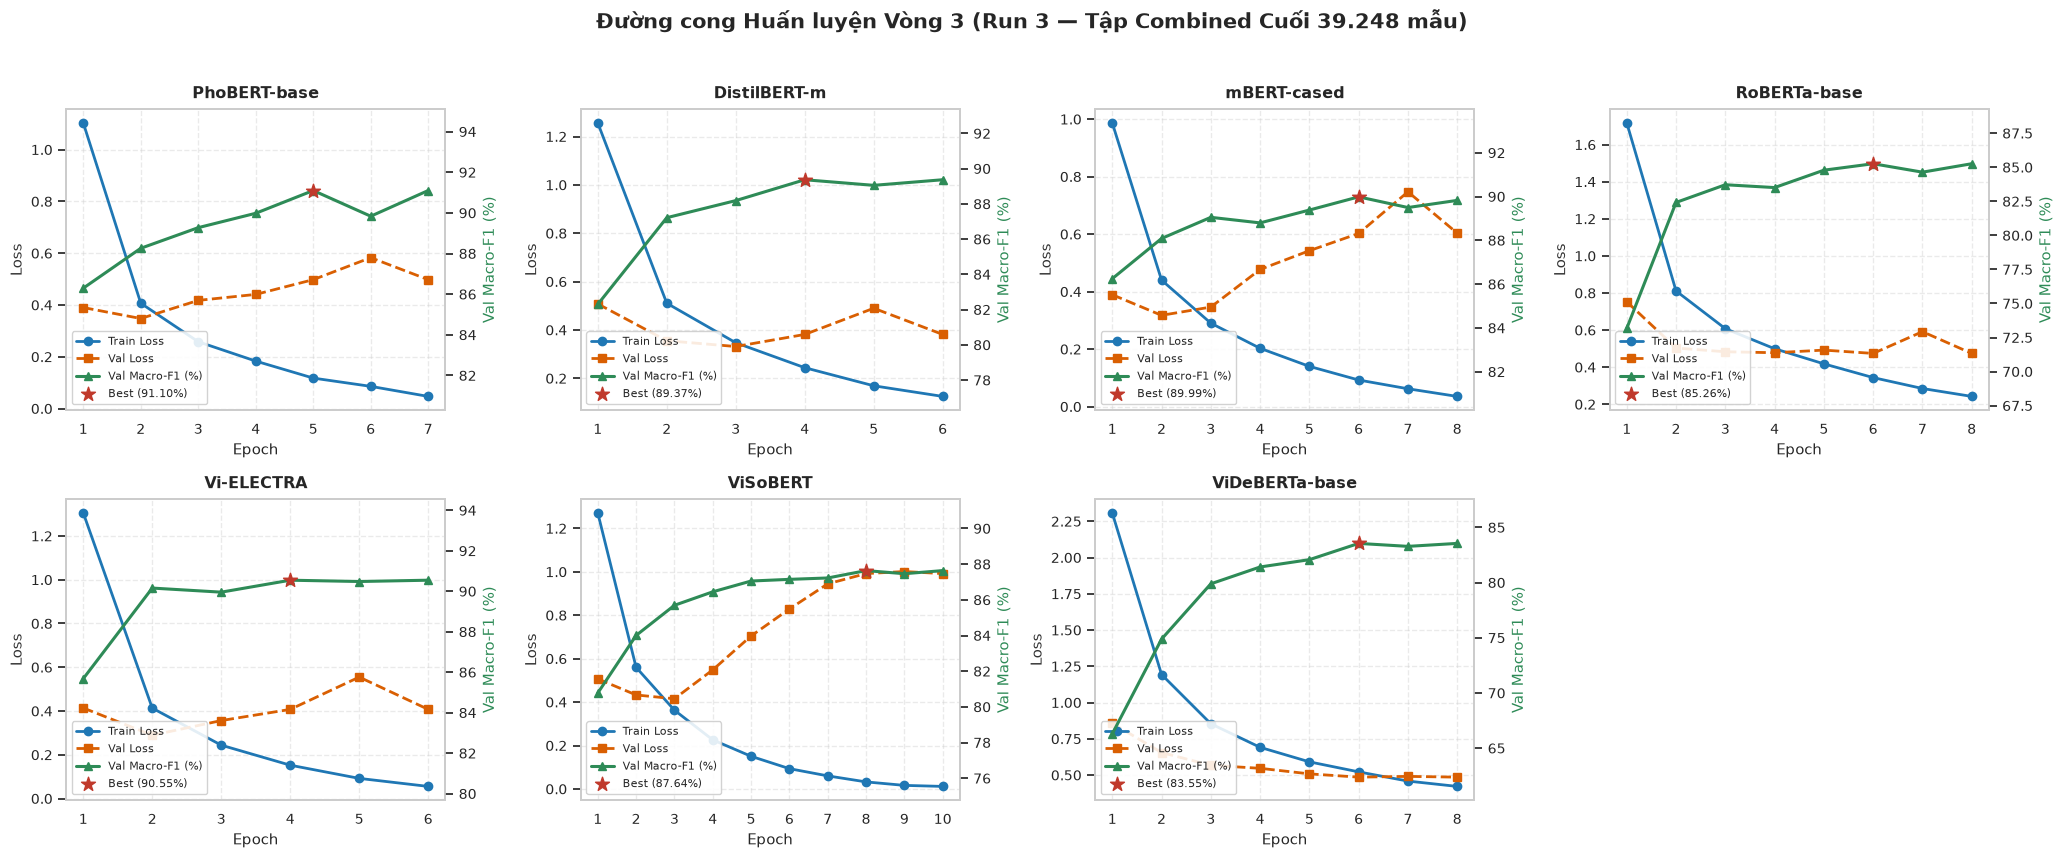

[Đã lưu biểu đồ] B7_01_so_sanh_don_le_va_ensemble.png, B7_01_so_sanh_don_le_va_ensemble.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B7_run3_ensemble


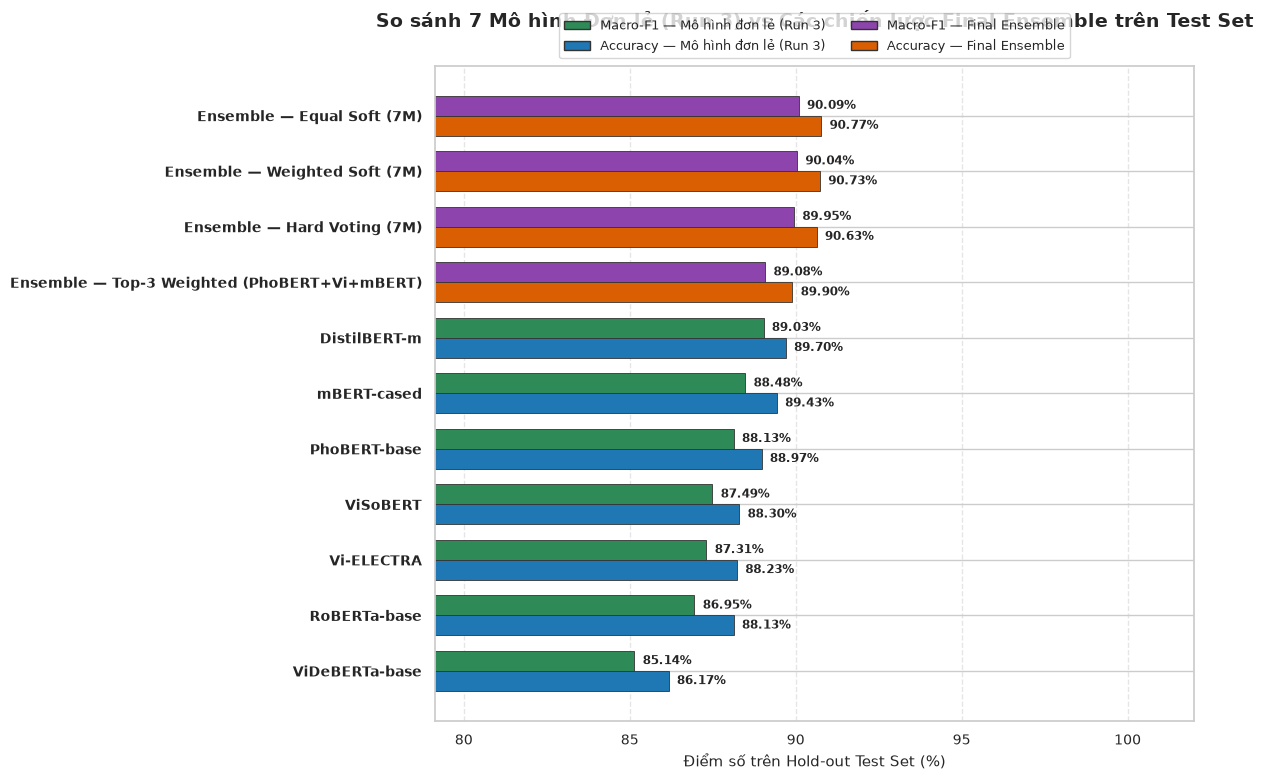

[Đã lưu biểu đồ] B7_02_benchmark_toc_do_suy_luan.png, B7_02_benchmark_toc_do_suy_luan.pdf -> D:\Document 2025 Backup\XuLyNgonNguTuNhien\Vi-ESG-Bert-LuuTuanTrinh\workspace_outputs\figures\B7_run3_ensemble


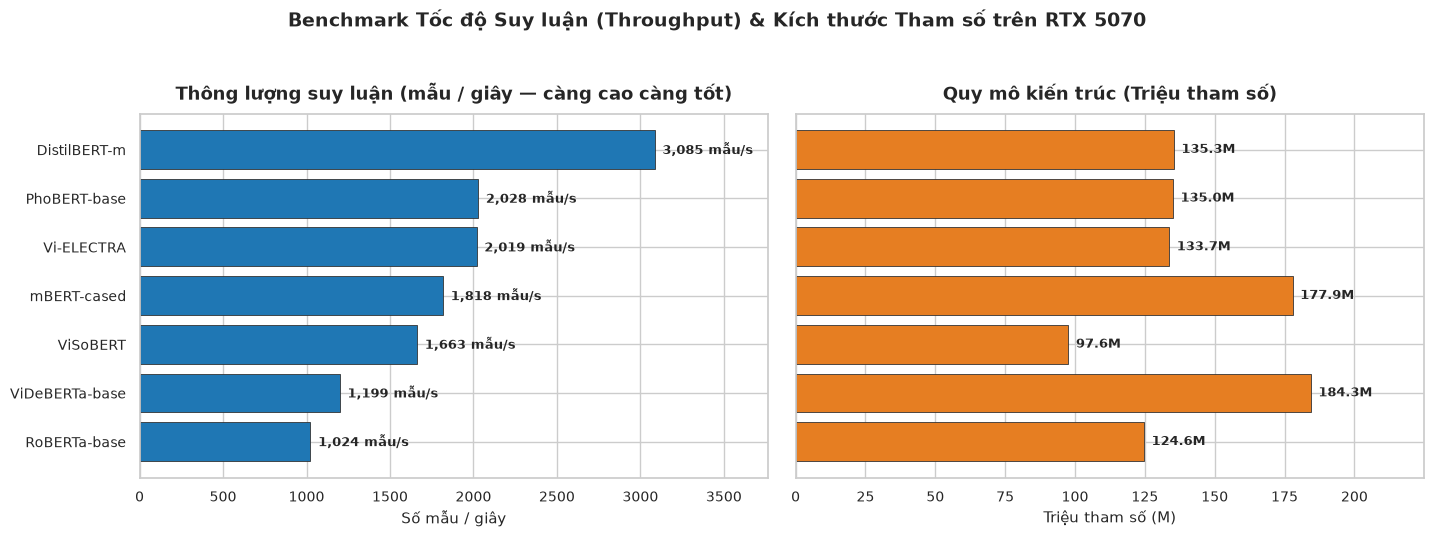


=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B7_run3_ensemble ===
  - B7_00_learning_curves_run3.pdf
  - B7_00_learning_curves_run3.png
  - B7_01_so_sanh_don_le_va_ensemble.pdf
  - B7_01_so_sanh_don_le_va_ensemble.png
  - B7_02_benchmark_toc_do_suy_luan.pdf
  - B7_02_benchmark_toc_do_suy_luan.png


In [6]:
# Bước 7.6 — Xuất 3 biểu đồ của Bước B7 vào workspace_outputs/figures/B7_run3_ensemble/
run3_histories = {}
for spec in cfg.get_active_models():
    hp = METRICS_DIR / f"run3_{spec.short_name}_history.csv"
    if hp.exists():
        run3_histories[spec.display_name] = pd.read_csv(hp)

if run3_histories:
    fig_lc3 = plot_learning_curves_grid(
        histories=run3_histories,
        title="Đường cong Huấn luyện Vòng 3 (Run 3 — Tập Combined Cuối 39.248 mẫu)",
        save_dir=FIG_DIR,
        filename_stem="B7_00_learning_curves_run3",
        dpi=cfg.figure_dpi,
        save_pdf=cfg.save_pdf_figures,
    )
    plt.show()

fig_ens = plot_run3_and_ensemble_comparison(
    run3_and_ens_df=b7_summary_df,
    save_dir=FIG_DIR,
    filename_stem="B7_01_so_sanh_don_le_va_ensemble",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

single_r3_df = b7_summary_df[b7_summary_df["run_tag"] == "run3"]
fig_bench = plot_inference_benchmark(
    bench_df=single_r3_df,
    save_dir=FIG_DIR,
    filename_stem="B7_02_benchmark_toc_do_suy_luan",
    dpi=cfg.figure_dpi,
    save_pdf=cfg.save_pdf_figures,
)
plt.show()

print("\n=== DANH SÁCH FILE BIỂU ĐỒ ĐÃ LƯU TẠI B7_run3_ensemble ===")
for p in sorted(FIG_DIR.glob("*")):
    print(f"  - {p.name}")